# Persons Involved in the Group

The five students are:
- Student 1
- Student 2
- Student 3
- Student 4
- Student 5

# Goal of this Practice

The goal is to study atmospheric heat waves in Brest (France) using statistical methods and recent machine learning approaches. First, the project will focus on historical data (1940-2025). Then, it will focus on the future (until 2100) under several CO2 emissions scenarios.

# Evaluation of this Practice

I will evaluate 3 main components:


1. the quality of the code (must be concise and well written)
2. the quality of the outputs (never forget that you are dealing with physical variables, so use the correct units)
3. the explanation of the method (describe mathematically the chosen approach, write directly into to notebook using Latex)
4. the discussion about your results (don't forget that data and results have a physical meaning)

# Import Libraries

- matplotlib (2D plotting)
- pylab (scientific computing)
- pandas (data structures and data analysis tools)
- torch (advanced machine learning)


In [ ]:
%matplotlib inline
%pylab inline
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

Populating the interactive namespace from numpy and matplotlib


# The ERA5 Database

Researchers use ECMWF’s ERA5 atmospheric reanalysis to examine surface air temperature (2-meter temperature) trends, seasonal variability, and extreme heat events in Brest, France. Because Brest is a coastal port city in Brittany, localized climate studies rely on ERA5's high hourly temporal resolution and continuous spatial coverage (9 km) to bridge gaps between land-based weather station observations and marine conditions. By integrating decades of historical assimilated data (from 1940 to the present), ERA5 allows climatologists to isolate long-term warming trends, model the Atlantic Ocean's moderating influence on local temperatures, and analyze how coastal mesoclimates respond to broader regional climate change.

# Part 1: Statistical Analysis of Atmospheric Heat Waves

In [ ]:
# read data
daily_temp_brest = pd.read_csv('/content/daily_temp_brest.csv')
print(daily_temp_brest)

       valid_time      mean
0      1940-01-01  3.484619
1      1940-01-02  2.409851
2      1940-01-03  6.619751
3      1940-01-04  7.831360
4      1940-01-05  8.317627
...           ...       ...
31407  2025-12-27  5.816040
31408  2025-12-28  5.751068
31409  2025-12-29  5.455261
31410  2025-12-30  5.287292
31411  2025-12-31  3.994019

[31412 rows x 2 columns]


[link text](https:// [link text](https://))Compute the seasonal cycle of the mean temperature in Brest. To do so, for each day of the year (between 1 and 365), compute the quantiles at 10%, 50%, and 90%. Apply a 1-month rolling mean to smooth the data. Plot the corresponding curves and comment on this figure.

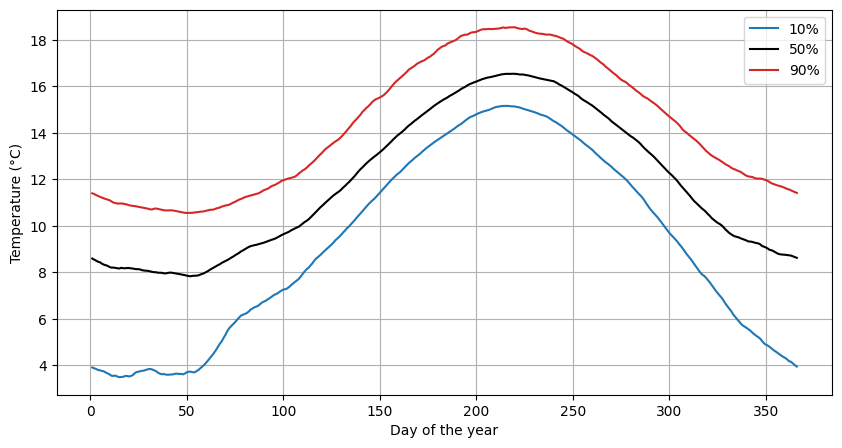

In [ ]:
#We change the type of the dates (which are saved first as str) to real dates
daily_temp_brest['valid_time'] = pd.to_datetime(daily_temp_brest['valid_time'])
#days have all days of the data written from 1 to 365(or 366) repeated until the end of the data
days= daily_temp_brest['valid_time'].dt.dayofyear
#We calculate the quantiles but we keep them in a table
q = (daily_temp_brest.groupby(days)['mean'].quantile([0.1, 0.5, 0.9]).unstack())
#We use this already implemented function to apply the 1-month rolling mean
#But since the first/last days don't have enough days before/after them we will consider days as a loop
w = 30
q_ext = pd.concat([q.iloc[-w:], q, q.iloc[:w]])
q_smooth = q_ext.rolling(window=w, center=True).mean().iloc[w:-w]
#ploting the corresponding curves
plt.figure(figsize=(10, 5))
plt.plot(q_smooth.index, q_smooth[0.1], label='10%', color='tab:blue')
plt.plot(q_smooth.index, q_smooth[0.5], label='50%', color='black')
plt.plot(q_smooth.index, q_smooth[0.9], label='90%', color='tab:red')
plt.xlabel("Day of the year")
plt.ylabel('Temperature (°C)')
plt.grid()
plt.legend()
plt.show()



# Comments



We realize that the three plots are one over the other (th coldest below and the hottest above), and their shape is similar
(they deacreasing in the first 10 days then they go up to the highest temperature afterapproximatly 220 days then they deacrease till the end of the year)

Compute the duration and intensity of the different heat waves during the period 1940 to 2025. The duration corresponds to the number of consecutive days exceeding the 90% quantile. The intensity is defined as the mean temperature anomaly during those consecutive days.

In [ ]:
#For each day: we put the high (90%) and average (50%) temperature
# day 366 (leap years) -> 365, otherwise NaN
days_c = days.clip(upper=365)
high    = days_c.map(q_smooth[0.9])
average = days_c.map(q_smooth[0.5])

#hot day is when the mean temperature is higher than the 90% quantile
#anomalie is the difference between the temperature of that day and the average (median) temperature of that day
hot = daily_temp_brest['mean'] > high
anomalie = daily_temp_brest['mean'] - average

#a new label starts each time `hot` switches between True and False,
#so each block of consecutive days gets its own number
run = (hot != hot.shift()).cumsum()

#For each series of hot days: duration = number of days, intensity = mean anomaly
waves = anomalie[hot].groupby(run[hot]).agg(duration='size', intensity='mean')

#Start date of each wave (year used for the color of the scatter plot)
waves['year'] = daily_temp_brest.loc[hot, 'valid_time'].groupby(run[hot]).first().dt.year

print(waves)

      duration  intensity  year
2            1   3.161048  1940
4            1   3.220718  1940
6            1   2.780701  1940
8            2   3.153336  1940
10           3   3.505522  1940
...        ...        ...   ...
2968         5   3.953333  2025
2970         1   3.442112  2025
2972         4   4.085072  2025
2974         1   3.096144  2025
2976         1   3.238266  2025

[1488 rows x 3 columns]


Make the following scatter plot of the heat waves in Brest, with: x-axis representing duration, y-axis representing intensity, and the color representing the year of appearance. Comment on this figure.

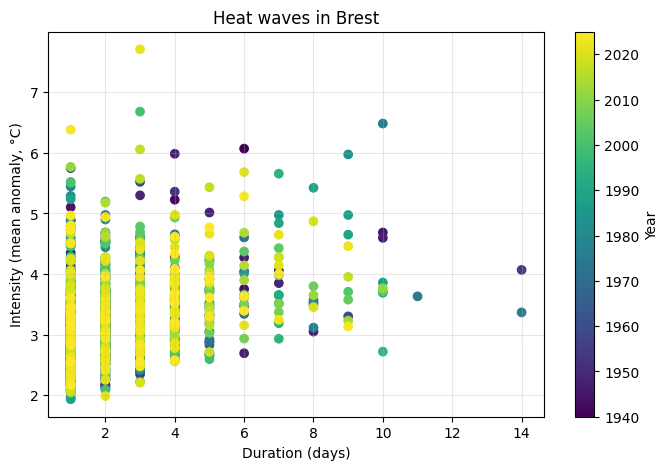

In [ ]:

plt.figure(figsize=(8, 5))
sc = plt.scatter(waves['duration'], waves['intensity'], c=waves['year'], cmap='viridis')
plt.colorbar(sc, label='Year')
plt.xlabel('Duration (days)')
plt.ylabel('Intensity (mean anomaly, °C)')
plt.title('Heat waves in Brest')
plt.grid(alpha=0.3)
plt.show()

**Comments**

Wr realize that

# Part 2: Machine Learning Methods for the Prediction of Extreme Events in the Future

In [ ]:
# read data
yearly_temp_brest = pd.read_csv('/content/yearly_temp_brest.csv')
print(yearly_temp_brest)

    valid_time        max       min         co2
0   1940-01-01  24.790497 -3.994019  310.000000
1   1941-01-01  24.934845 -1.216583  311.162500
2   1942-01-01  25.541260 -1.027679  312.329359
3   1943-01-01  27.316742  1.669037  313.500594
4   1944-01-01  25.795715 -0.246552  314.676222
..         ...        ...       ...         ...
81  2021-01-01  28.604187 -1.346619  419.789832
82  2022-01-01  34.178619  1.063812  421.364044
83  2023-01-01  27.587494  0.408691  422.944159
84  2024-01-01  29.494080 -0.848175  424.530200
85  2025-01-01  27.788269  1.253174  428.501735

[86 rows x 4 columns]


Plot and comment on the maximum annual temperature in Brest from 1940 to 2025.

/tmp/ipykernel_3039/4002073798.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


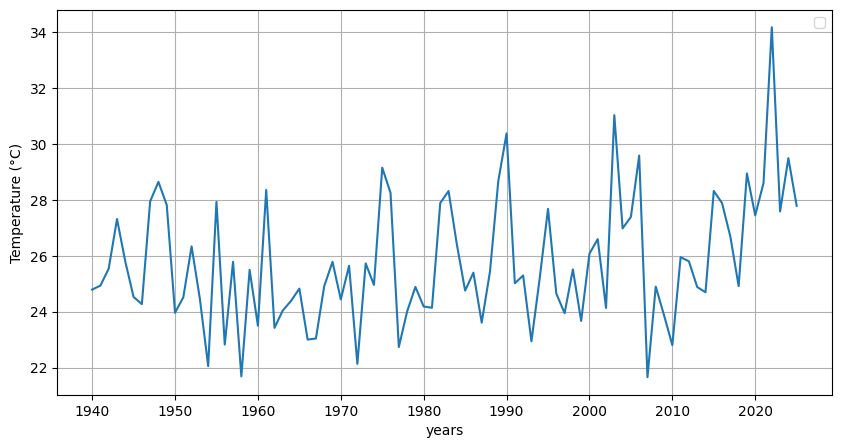

In [ ]:
#We change the type of the dates (which are saved first as str) to real dates
yearly_temp_brest['valid_time'] = pd.to_datetime(yearly_temp_brest['valid_time'])
#ploting the corresponding curves
plt.figure(figsize=(10, 5))
plt.plot(yearly_temp_brest['valid_time'], yearly_temp_brest['max'], color='tab:blue')
plt.xlabel("years")
plt.ylabel('Temperature (°C)')
plt.grid()
plt.legend()
plt.show()

Compute the correlation between the maximum annual temperature in Brest and the global annual CO2. To increase the linear correlation coefficient, test several transformations of those two variables.

In [ ]:
corr = yearly_temp_brest["max"].corr(yearly_temp_brest["co2"])
print(corr)

0.3143260373611496


In [ ]:


from pandas.plotting import scatter_matrix
d= yearly_temp_brest.copy()
attributes=
scatter_matrix(d[attributes],figsize=(12,8))
corr=d.corr(numeric_only=True)
print(corr)


SyntaxError: invalid syntax (4235910579.py, line 3)

Use recent machine learning methods to provide probabilistic predictions (not deterministic) of maximum annual temperatures until 2100, conditionally on the three main climate scenarios. These SSPs differ in their level of annual CO2 emissions. Do not forget to present your approach mathematically and to justify your choice.

In [ ]:
# read data
yearly_future_co2 = pd.read_csv('/content/yearly_future_co2.csv')
print(yearly_future_co2)

    valid_time    ssp1-2.6    ssp2-4.5    ssp5-8.5
0   2026-01-01  420.780225  420.188542  421.121677
1   2027-01-01  421.558613  423.729506  425.754016
2   2028-01-01  422.333331  427.165818  430.437310
3   2029-01-01  423.102552  430.500572  435.172120
4   2030-01-01  423.864459  433.736770  439.959014
..         ...         ...         ...         ...
70  2096-01-01  405.235885  525.328317  905.708594
71  2097-01-01  403.933331  525.761931  915.671389
72  2098-01-01  402.625279  526.182729  925.743774
73  2099-01-01  401.313558  526.591091  935.926955
74  2100-01-01  400.000000  526.987384  946.222152

[75 rows x 4 columns]


## Méthode alternative testée : réseau de neurones à densité de mélange (MDN)

**Idée.** Un réseau de neurones classique prédit une valeur unique (prédiction déterministe). Un réseau à densité de mélange (*Mixture Density Network*) prédit à la place **les paramètres d'une loi de probabilité** : pour une année dont le CO$_2$ vaut $c$, il fournit directement la distribution de $T_{\max}$ conditionnelle à ce CO$_2$. On obtient ainsi une prédiction probabiliste, et non une température unique.

**Entrée.** On utilise le logarithme du CO$_2$, centré et réduit à partir de l'historique :
$$z=\frac{\ln(\mathrm{CO}_2)-\overline{\ln(\mathrm{CO}_2)}}{s_{\ln(\mathrm{CO}_2)}}$$

**Architecture** (une couche cachée de $16$ neurones, $K=3$ composantes) :
$$h(z)=\tanh\!\big(W_1 z+b_1\big)\in\mathbb R^{16},\qquad o=W_2\,h(z)+b_2\in\mathbb R^{3K}=\mathbb R^{9}$$
Les 9 sorties brutes sont réparties en trois groupes $(\ell_k)$, $(m_k)$, $(s_k)$, puis transformées pour avoir un sens physique :
$$\pi_k(z)=\frac{e^{\ell_k}}{\sum_{j=1}^{K}e^{\ell_j}}\ (\text{poids positifs, de somme }1),\qquad \mu_k(z)=m_k+25\ (^\circ\mathrm C),\qquad \sigma_k(z)=e^{s_k}>0$$

**Loi prédite.** La distribution de la température maximale est un mélange de gaussiennes :
$$p(T\mid z)=\sum_{k=1}^{K}\pi_k(z)\;\mathcal N\!\big(T;\ \mu_k(z),\ \sigma_k(z)^2\big)$$
Avec plusieurs composantes, le mélange peut reproduire une distribution asymétrique, par exemple une queue plus longue du côté chaud grâce à une composante large de faible poids.

**Apprentissage.** Les poids $\theta=(W_1,b_1,W_2,b_2)$ sont obtenus en maximisant la vraisemblance des observations $(z_t,T_t)_{t=1940}^{2025}$, c'est-à-dire en minimisant la log-vraisemblance négative avec une pénalisation $L^2$ (*weight decay*) :
$$\hat\theta=\arg\min_\theta\ -\sum_{t}\ln\!\Big[\sum_{k=1}^{K}\pi_k(z_t)\,\mathcal N\big(T_t;\mu_k(z_t),\sigma_k(z_t)^2\big)\Big]+\lambda\|\theta\|_2^2$$
La minimisation est faite par descente de gradient (Adam). Pour prédire, on tire au hasard une composante $k$ avec probabilité $\pi_k(z)$, puis une valeur dans $\mathcal N(\mu_k,\sigma_k^2)$, et on répète le tirage pour estimer les quantiles.

MDN K=1 : NLL moyenne  train = 2.088 | test = 2.516
MDN K=3 : NLL moyenne  train = 2.007 | test = 2.508


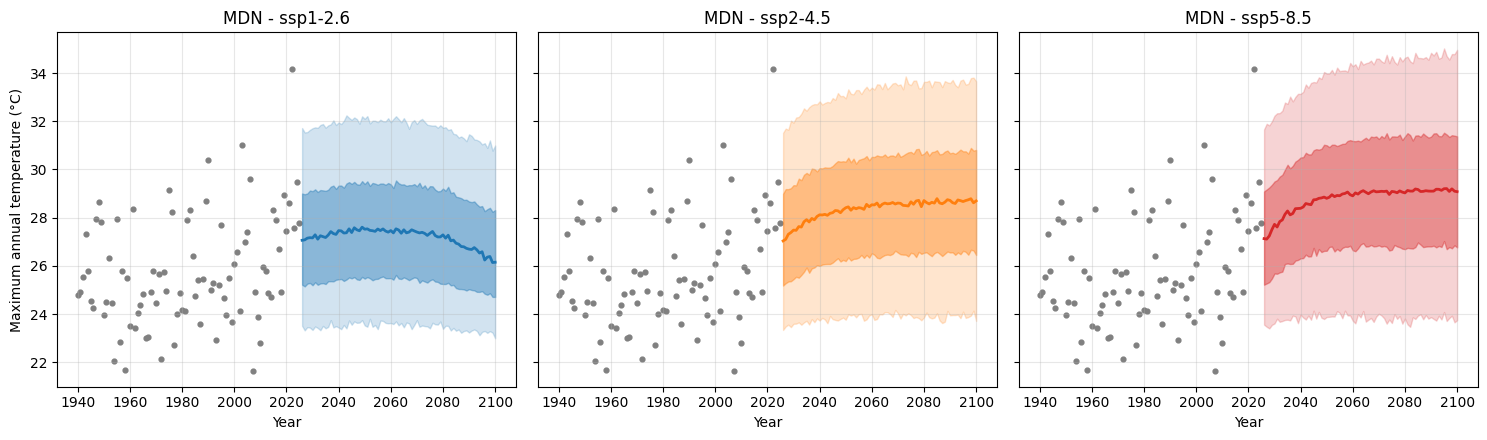

In [ ]:


ln_co2 = np.log(yearly_temp_brest['co2'].values)
m, s = ln_co2.mean(), ln_co2.std()
z_all = torch.tensor((ln_co2 - m) / s)[:, None]                  # (n, 1)
y_all = torch.tensor(yearly_temp_brest['max'].values)[:, None]   # (n, 1)
years = yearly_temp_brest['valid_time'].dt.year.values

class MDN(torch.nn.Module):
    def __init__(self, K=3, hidden=16):
        super().__init__()
        self.K = K
        self.body = torch.nn.Sequential(torch.nn.Linear(1, hidden), torch.nn.Tanh())
        self.head = torch.nn.Linear(hidden, 3 * K)                # K logits, K moyennes, K log-écarts-types
    def forward(self, z):
        logit, mu, log_sig = self.head(self.body(z)).chunk(3, dim=1)
        return logit, mu + 25.0, log_sig                          # +25 : centre la sortie sur l'ordre de grandeur de Tmax
    def nll(self, z, y):
        logit, mu, log_sig = self(z)
        log_pi = torch.log_softmax(logit, dim=1)                  # poids du mélange (somme = 1)
        log_comp = -0.5 * ((y - mu) / log_sig.exp()) ** 2 - log_sig - 0.5 * np.log(2 * np.pi)
        return -torch.logsumexp(log_pi + log_comp, dim=1)         # -log p(y|z) pour chaque point
    def sample(self, z, n):
        with torch.no_grad():
            logit, mu, log_sig = self(z)
            k = torch.multinomial(torch.softmax(logit, 1), n, replacement=True)   # choix de la composante
            mu, sig = mu.gather(1, k), log_sig.exp().gather(1, k)
            return mu + sig * torch.randn_like(mu)                                # (len(z), n)

def train_mdn(z, y, K=3, hidden=16, epochs=1500, wd=1e-2, seed=0):
    torch.manual_seed(seed)
    net = MDN(K, hidden).double()
    opt = torch.optim.Adam(net.parameters(), lr=1e-2, weight_decay=wd)   # weight_decay = régularisation L2
    for _ in range(epochs):
        opt.zero_grad()
        net.nll(z, y).mean().backward()
        opt.step()
    return net

# --- Validation temporelle : entraînement 1940-2005, test 2006-2025 (on juge sur des années jamais vues) ---
tr, te = years <= 2005, years > 2005
for K in (1, 3):
    net = train_mdn(z_all[tr], y_all[tr], K=K)
    with torch.no_grad():
        print('MDN K=%d : NLL moyenne  train = %.3f | test = %.3f' % (K, net.nll(z_all[tr], y_all[tr]).mean(), net.nll(z_all[te], y_all[te]).mean()))

# --- Prédictions 2026-2100 (réseau entraîné sur toutes les données, K=3) ---
net = train_mdn(z_all, y_all, K=3)
years_f = pd.to_datetime(yearly_future_co2['valid_time']).dt.year.values
qs = [0.05, 0.25, 0.5, 0.75, 0.95]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, sc, col in zip(axs, ['ssp1-2.6', 'ssp2-4.5', 'ssp5-8.5'], ['tab:blue', 'tab:orange', 'tab:red']):
    z_f = torch.tensor((np.log(yearly_future_co2[sc].values) - m) / s)[:, None]
    q = np.quantile(net.sample(z_f, 3000).numpy(), qs, axis=1)
    ax.scatter(years, yearly_temp_brest['max'], s=12, color='gray')
    ax.fill_between(years_f, q[0], q[4], color=col, alpha=0.2)
    ax.fill_between(years_f, q[1], q[3], color=col, alpha=0.4)
    ax.plot(years_f, q[2], color=col, lw=2)
    ax.set_title('MDN - ' + sc); ax.set_xlabel('Year'); ax.grid(alpha=0.3)
axs[0].set_ylabel('Maximum annual temperature (°C)')
plt.tight_layout(); plt.show()

MDN K=1 : NLL train = 2.088 | NLL test = 2.516
MDN K=3 : NLL train = 2.007 | NLL test = 2.508


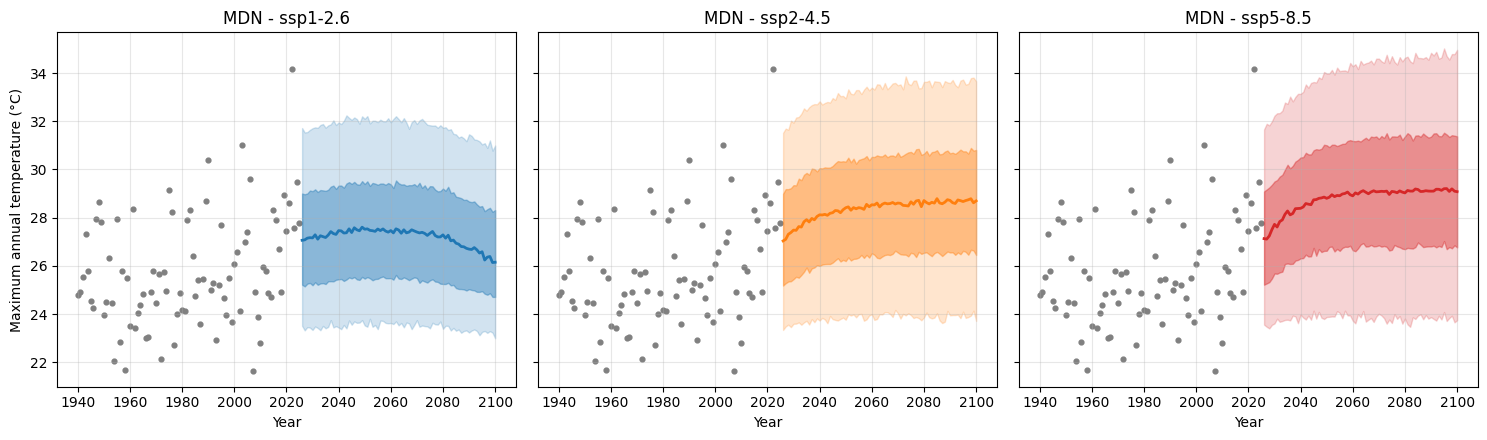

In [ ]:

# =====================================================
# 1. PREPARATION DES DONNEES
# =====================================================

ln_co2 = np.log(yearly_temp_brest["co2"].values)

m_co2 = ln_co2.mean()
s_co2 = ln_co2.std()

z_all = torch.tensor(
    ((ln_co2 - m_co2) / s_co2)[:, None]
)

y_all = torch.tensor(
    yearly_temp_brest["max"].values[:, None]
)

years = yearly_temp_brest["valid_time"].dt.year.values



# 2. DEFINITION DU RESEAU MDN


class MDN(torch.nn.Module):

    def __init__(self, K=3, hidden=16):
        super().__init__()

        self.K = K

        # Couche cachee : 1 entree -> 16 neurones
        self.hidden = torch.nn.Sequential(
            torch.nn.Linear(1, hidden),
            torch.nn.Tanh()
        )

        # Couche de sortie : 16 -> 3*K = 9 sorties
        self.output = torch.nn.Linear(hidden, 3 * K)

    def forward(self, z):

        h = self.hidden(z)

        # Vecteur de sortie o de dimension 9
        o = self.output(h)

        # Decoupage de o en trois groupes
        logits, m, s = o.chunk(3, dim=1)

        # Parametres du melange
        mu = m + 25.0

        return logits, mu, s

    def nll(self, z, y):

        logits, mu, s = self(z)

        # Logarithmes des poids du melange
        log_pi = torch.log_softmax(logits, dim=1)

        # Log-densite de chaque loi gaussienne
        log_comp = (
            -0.5 * ((y - mu) / torch.exp(s)) ** 2
            - s
            - 0.5 * np.log(2 * np.pi)
        )

        # Densite totale : melange des 3 gaussiennes
        log_density = torch.logsumexp(
            log_pi + log_comp, dim=1
        )

        # Log-vraisemblance negative
        return -log_density

    def sample(self, z, n):

        with torch.no_grad():

            logits, mu, s = self(z)

            # Choisir une composante selon ses probabilites
            pi = torch.softmax(logits, dim=1)

            k = torch.multinomial(
                pi, n, replacement=True
            )

            # Recuperer les parametres de la composante choisie
            mu_k = mu.gather(1, k)
            sigma_k = torch.exp(s).gather(1, k)

            # Tirer une temperature selon la loi choisie
            samples = (
                mu_k + sigma_k * torch.randn_like(mu_k)
            )

            return samples


# 3. ENTRAINEMENT DU RESEAU

def train_mdn(z, y, K=3, hidden=16,
              epochs=1500, wd=1e-2, seed=0):

    torch.manual_seed(seed)

    net = MDN(K, hidden).double()

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=1e-2,
        weight_decay=wd
    )

    for epoch in range(epochs):

        optimizer.zero_grad()

        loss = net.nll(z, y).mean()

        loss.backward()
        optimizer.step()

    return net

# 4. VALIDATION TEMPORELLE

train_mask = years <= 2005
test_mask = years > 2005

for K in (1, 3):

    net = train_mdn(
        z_all[train_mask],
        y_all[train_mask],
        K=K
    )

    with torch.no_grad():

        loss_train = net.nll(
            z_all[train_mask], y_all[train_mask]
        ).mean()

        loss_test = net.nll(
            z_all[test_mask], y_all[test_mask]
        ).mean()

    print(
        f"MDN K={K} : "
        f"NLL train = {loss_train.item():.3f} | "
        f"NLL test = {loss_test.item():.3f}"
    )


# =====================================================
# 5. ENTRAINEMENT SUR TOUTES LES DONNEES
# =====================================================

net = train_mdn(z_all, y_all, K=3)

years_f = pd.to_datetime(
    yearly_future_co2["valid_time"]
).dt.year.values

qs = [0.05, 0.25, 0.5, 0.75, 0.95]

fig, axs = plt.subplots(
    1, 3, figsize=(15, 4.5), sharey=True
)

scenarios = ["ssp1-2.6", "ssp2-4.5", "ssp5-8.5"]
colors = ["tab:blue", "tab:orange", "tab:red"]

for ax, sc, col in zip(axs, scenarios, colors):

    # CO2 futur normalise avec les statistiques historiques
    z_f = torch.tensor(
        ((np.log(yearly_future_co2[sc].values) - m_co2)
         / s_co2)[:, None]
    )

    # 3000 temperatures simulees par annee
    samples = net.sample(z_f, 3000).numpy()

    # Calcul des quantiles pour chaque annee
    q = np.quantile(samples, qs, axis=1)

    # Temperatures historiques
    ax.scatter(
        years,
        yearly_temp_brest["max"],
        s=12,
        color="gray"
    )

    # Intervalle entre les quantiles 5 % et 95 %
    ax.fill_between(
        years_f, q[0], q[4],
        color=col, alpha=0.2
    )

    # Intervalle entre les quantiles 25 % et 75 %
    ax.fill_between(
        years_f, q[1], q[3],
        color=col, alpha=0.4
    )

    # Mediane predite
    ax.plot(years_f, q[2], color=col, lw=2)

    ax.set_title("MDN - " + sc)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.3)

axs[0].set_ylabel("Maximum annual temperature (°C)")

plt.tight_layout()
plt.show()


Based on your probabilistic predictions, provide the distribution of the maximum annual temperature in 2100 for the three climate scenarios (SSPs). Based on your predictions, what is the probability of exceeding 40°C in Brest, by 2100, for the three climate scenarios?

In [ ]:
# Le reseau doit etre entraine sur toutes les donnees historiques
net = train_mdn(z_all, y_all, K=3)

future_years = pd.to_datetime(
    yearly_future_co2["valid_time"]
).dt.year.values

# Indice correspondant a l'annee 2100
idx = np.where(future_years == 2100)[0][0]

scenarios = ["ssp1-2.6", "ssp2-4.5", "ssp5-8.5"]

for sc in scenarios:

    # CO2 du scenario considere en 2100
    co2_2100 = yearly_future_co2[sc].values[idx]

    # Normalisation identique a celle des donnees historiques
    z_2100 = torch.tensor(
        [[(np.log(co2_2100) - m_co2) / s_co2]],
        dtype=torch.double
    )

    with torch.no_grad():

        # Parametres du melange en 2100
        logits, mu, log_sig = net(z_2100)

        pi = torch.softmax(logits, dim=1)
        sigma = torch.exp(log_sig)

        # Probabilite de depasser 40 degres pour chaque gaussienne
        tail = 0.5 * torch.erfc(
            (40.0 - mu) / (sigma * np.sqrt(2))
        )

        # Probabilite totale : somme ponderee des probabilites
        prob_40 = (pi * tail).sum().item()

        # Simulations pour estimer les quantiles de la distribution
        samples = net.sample(z_2100, 100000).cpu().numpy()[0]

        quantiles = np.quantile(
            samples, [0.05, 0.25, 0.50, 0.75, 0.95]
        )

    print(f"\nScenario : {sc}")
    print("Poids :", pi.cpu().numpy()[0])
    print("Moyennes (°C) :", mu.cpu().numpy()[0])
    print("Ecarts-types (°C) :", sigma.cpu().numpy()[0])
    print("Quantiles 5%, 25%, 50%, 75%, 95% :", quantiles)
    print(f"P(Tmax > 40 °C) = {100 * prob_40:.4f} %")


Scenario : ssp1-2.6
Poids : [0.20582045 0.05758791 0.73659163]
Moyennes (°C) : [24.7329665  25.22361006 27.09484989]
Ecarts-types (°C) : [0.60812208 2.33390281 2.46148586]
Quantiles 5%, 25%, 50%, 75%, 95% : [23.11944853 24.72474991 26.15479545 28.1548082  30.76573395]
P(Tmax > 40 °C) = 0.0000 %

Scenario : ssp2-4.5
Poids : [0.03296004 0.00327281 0.96376715]
Moyennes (°C) : [25.23513644 24.59001714 28.84792261]
Ecarts-types (°C) : [0.34968466 2.69315316 2.99435304]
Quantiles 5%, 25%, 50%, 75%, 95% : [23.92251514 26.55697941 28.68239482 30.75851975 33.69408012]
P(Tmax > 40 °C) = 0.0094 %

Scenario : ssp5-8.5
Poids : [0.02290764 0.00166851 0.97542386]
Moyennes (°C) : [25.26324398 24.51990862 29.27366292]
Ecarts-types (°C) : [0.31853994 3.05465532 3.35422745]
Quantiles 5%, 25%, 50%, 75%, 95% : [23.72887216 26.79124678 29.14849623 31.4482388  34.75873799]
P(Tmax > 40 °C) = 0.0675 %


Make the same study for the minimum annual temperatures in Brest. You can try a different approach to generate your predictions (without including the mathematical formulation).